SearchResult containing 3 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 07 2019    QLP    1800    49929975      0.0
  1 TESS Sector 34 2021    QLP     600    49929975      0.0
  2 TESS Sector 88 2025    QLP     200    49929975      0.0

=== Sector 7 | cámara 2 CCD 4 | N=1086 ===
CBV no disponible/compatible (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.).
-> usando RegressionCorrector con sap_bkg, sap_x, sap_y

=== Sector 34 | cámara 2 CCD 4 | N=3474 ===
CBV no disponible/compatible (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.).
-> usando RegressionCorrector con sap_bkg, sap_x, sap_y

=== Sector 88 | cámara 2 CCD 4 | N=11718 ===
CBV no disponible/compatible (AssertionError: cbvCorrector expects light curve to be passed in e-/s units.).
-> usando RegressionCorr

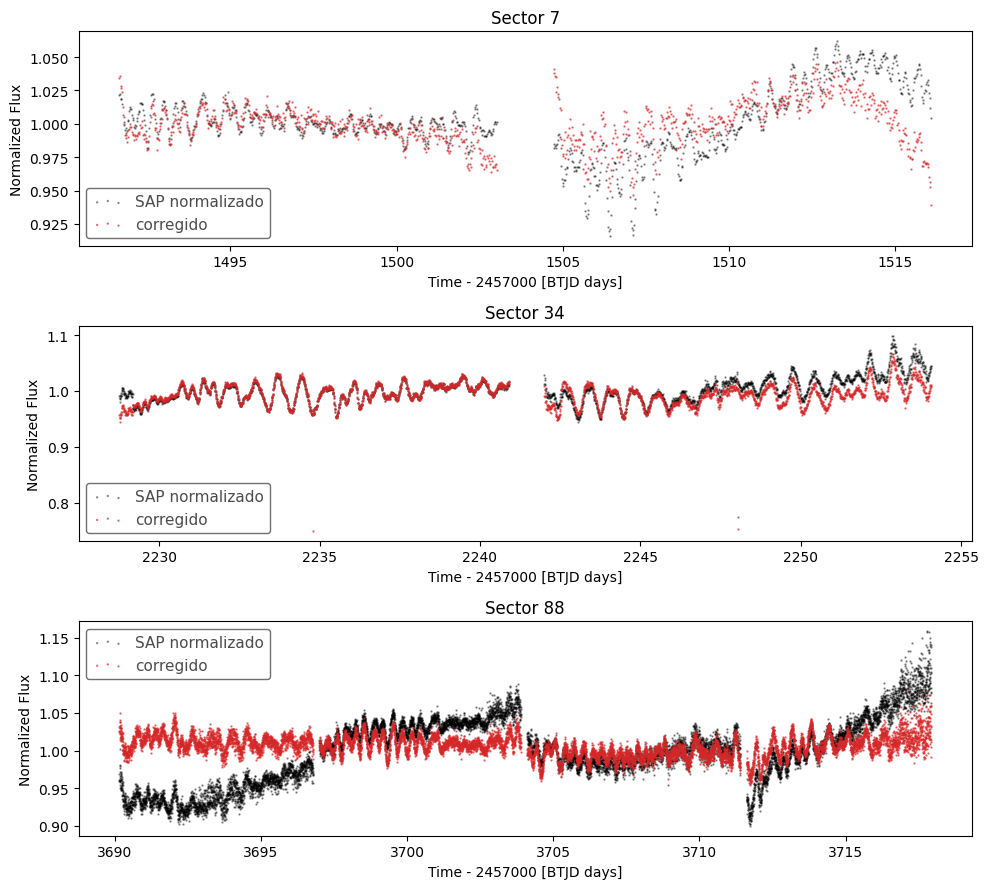

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from lightkurve.correctors import CBVCorrector, RegressionCorrector, DesignMatrix
 
TIC = "TIC 49929975"
 
# 1) Descargar solo QLP (un LightCurve por sector)
sr = lk.search_lightcurve(TIC, author="QLP")
print(sr)
lcs = sr.download_all(flux_column="sap_flux", quality_bitmask="default")
# Importante: se usa SAP_FLUX (sin corregir). KSPSAP_FLUX ya viene detrended
# por QLP y aplicar CBVs encima corregiría dos veces.
 
results = {}
for lc in lcs:
    sector = lc.meta["SECTOR"]
    print(f"\n=== Sector {sector} | cámara {lc.meta.get('CAMERA')} "
          f"CCD {lc.meta.get('CCD')} | N={len(lc)} ===")
    lc = lc.remove_nans().normalize()
 
    try:
        # interpolate_cbvs=True por si la cadencia de los CBV no coincide
        # exactamente con la de la curva QLP (cadenceno distinto)
        cbvc = CBVCorrector(lc, interpolate_cbvs=True, extrapolate_cbvs=True)
        cbvc.plot_cbvs(cbv_type=["SingleScale", "Spike"], cbv_indices="ALL")
        plt.savefig(f"cbvs_s{sector:02d}.png", dpi=150); plt.close("all")
 
        # Ajuste regularizado (ridge) como en el tutorial
        cbvc.correct(cbv_type=["SingleScale", "Spike"],
                     cbv_indices=[np.arange(1, 9), "ALL"],
                     alpha_bounds=[1e-4, 1e4],
                     target_over_score=0.5, target_under_score=0.8)
        cbvc.diagnose()
        plt.savefig(f"diagnose_s{sector:02d}.png", dpi=150); plt.close("all")
 
        print("over-fitting :", cbvc.over_fitting_score())
        print("under-fitting:", cbvc.under_fitting_score())
        results[sector] = (lc, cbvc.corrected_lc)
 
    except Exception as e:
        # Plan B: regresión sobre columnas propias de QLP (fondo y centroides)
        print(f"CBV no disponible/compatible ({type(e).__name__}: {e}).")
        print("-> usando RegressionCorrector con sap_bkg, sap_x, sap_y")
        cols = [c for c in ("sap_bkg", "sap_x", "sap_y") if c in lc.columns]
        dm = DesignMatrix(lc[cols].to_pandas().fillna(0), name="systematics")
        dm = dm.pca(3).append_constant()
        corr = RegressionCorrector(lc).correct(dm)
        results[sector] = (lc, corr)
 
# 2) Comparación antes / después
fig, axes = plt.subplots(len(results), 1, figsize=(10, 3 * len(results)), squeeze=False)
for ax, (sec, (raw, cor)) in zip(axes[:, 0], results.items()):
    raw.scatter(ax=ax, c="k", s=2, alpha=0.4, label="SAP normalizado")
    cor.scatter(ax=ax, c="tab:red", s=2, alpha=0.6, label="corregido")
    ax.set_title(f"Sector {sec}")
plt.tight_layout()
plt.savefig("qlp_before_after.png", dpi=150)
 
# 3) Unir sectores corregidos
corrected = lk.LightCurveCollection([c for _, c in results.values()]).stitch()
corrected.to_fits("tic49929975_qlp_corrected.fits", overwrite=True)
print(corrected)

In [ ]:


import astropy.units as u
from astropy.table import Table, vstack
 
tablas = {}
for sec in (7, 34, 88):
    if sec not in results:
        print(f"Sector {sec}: no se obtuvo curva corregida, se omite.")
        continue
    raw, cor = results[sec]
    t = Table()
    t["time_btjd"] = np.asarray(cor.time.value)               # BJD - 2457000
    t["flux_raw_norm"] = (np.asarray(raw.flux.value) if len(raw) == len(cor)
                          else np.full(len(cor), np.nan))
    t["flux_corr"] = np.asarray(cor.flux.value)
    t["flux_corr_err"] = np.asarray(cor.flux_err.value)
    t["quality"] = (np.asarray(cor.quality) if "quality" in cor.colnames
                    else np.zeros(len(cor), dtype=int))
    t["time_btjd"].unit = u.d
    t["time_btjd"].description = "BJD_TDB - 2457000"
    t["flux_corr"].description = "Flujo SAP normalizado y corregido con CBVs"
    t.meta["TARGET"] = TIC
    t.meta["SECTOR"] = sec
    t.meta["PIPELINE"] = "QLP + CBVCorrector (lightkurve)"
    t.sort("time_btjd")
 
    t.write(f"tic49929975_s{sec:02d}_qlp_corrected.ecsv", format="ascii.ecsv", overwrite=True)
    t.write(f"tic49929975_s{sec:02d}_qlp_corrected.fits", format="fits", overwrite=True)
    tablas[sec] = t
    print(f"\nSector {sec}: {len(t)} filas")
    print(t)


Sector 7: 1086 filas
    time_btjd      flux_raw_norm     flux_corr         flux_corr_err     quality
        d                                                                       
------------------ ------------- ------------------ -------------------- -------
1491.6614229398592      1.021649 1.0346322564960042 0.007273568664904254    4096
1491.6822566336243     1.0223376  1.036121322988086 0.007273568664904254       0
1491.7030903270872     1.0188009 1.0268655315294066 0.007273568664904254       0
1491.7239240201027     1.0184151 1.0281076829859839 0.007273568664904254       0
1491.7447577127157      1.015048 1.0238128391889982 0.007273568664904254       0
1491.7655914047857     1.0064172 1.0128871591603046 0.007273568664904254       0
1491.7864250963698     1.0012326  1.005296210282605 0.007273568664904254       0
 1491.807258787331     0.9989949 0.9998756571338018 0.007273568664904254       0
1491.8280924777343     0.9954216 0.9914632525538729 0.007273568664904254       0
      

In [8]:
tabla_7 = tablas.get(7)
tabla_34 = tablas.get(34)
tabla_88 = tablas.get(88)


=== Sector 7 | N=1064 | baseline=24.35 d ===
LS : P=8.118017 d  power=0.1939  FAP(baluev)=1.306e-46  FAP(bootstrap)=0.000e+00
PDM: P=0.104033 d  theta_min=0.7090  FAP(perm)=9.901e-03


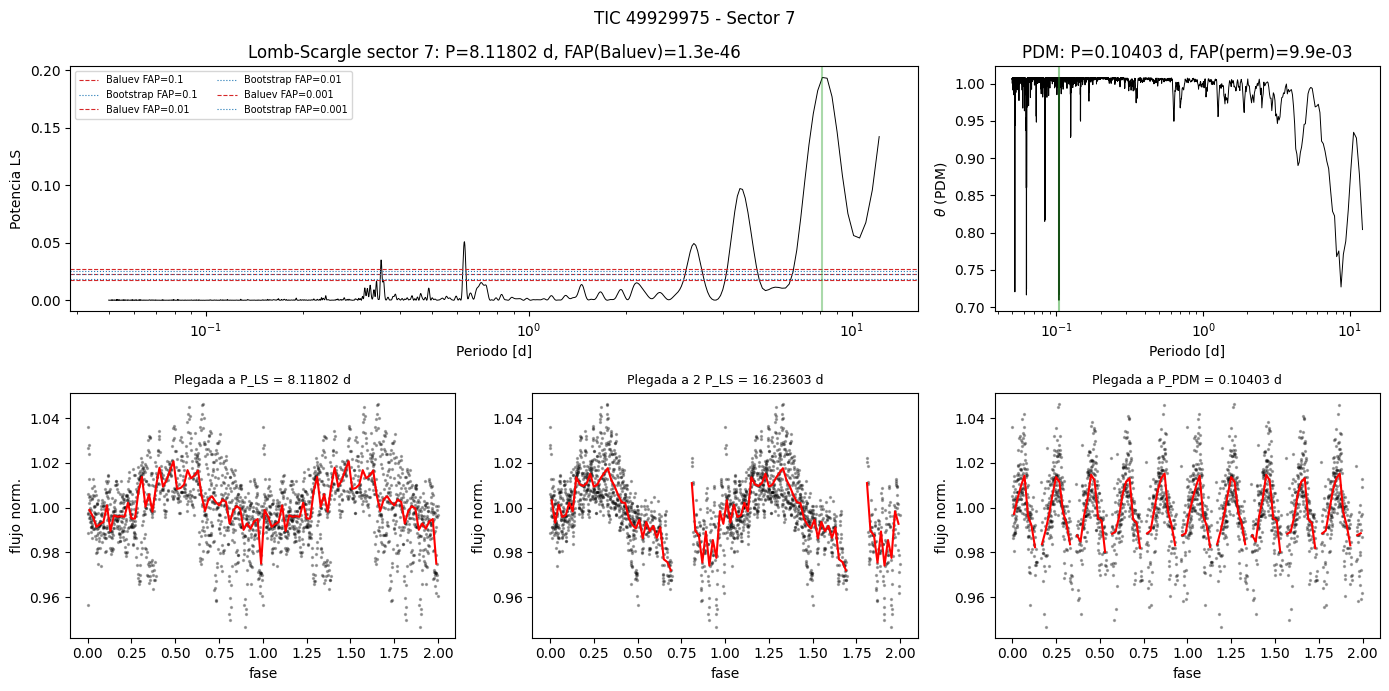

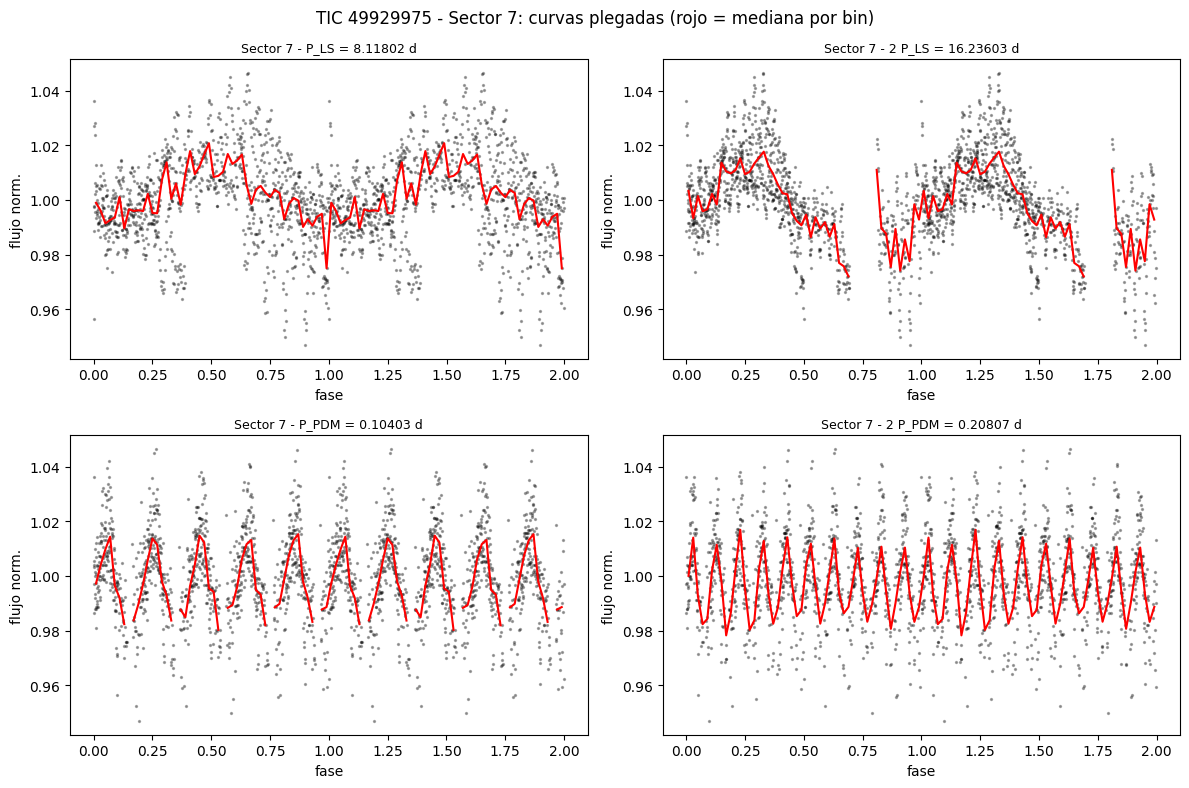


=== Sector 34 | N=2804 | baseline=22.84 d ===
LS : P=0.798600 d  power=0.2015  FAP(baluev)=1.287e-133  FAP(bootstrap)=0.000e+00
PDM: P=0.795817 d  theta_min=0.8059  FAP(perm)=9.901e-03


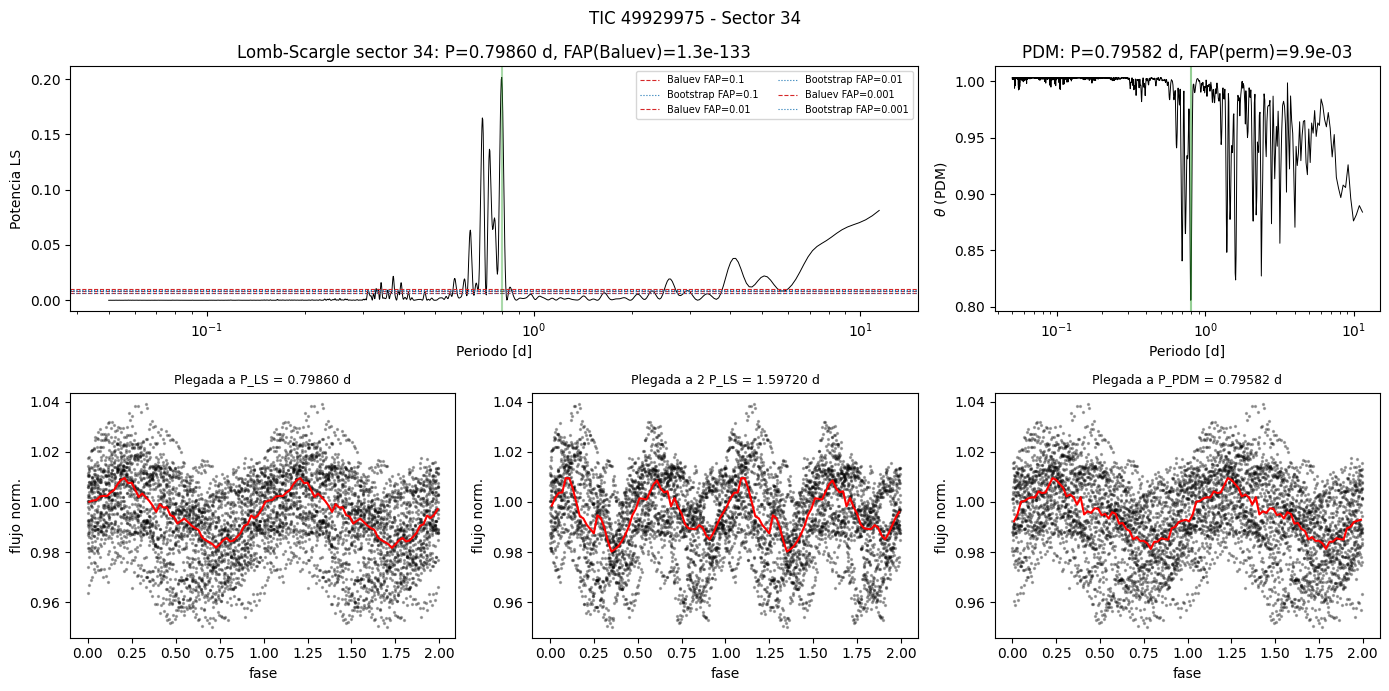

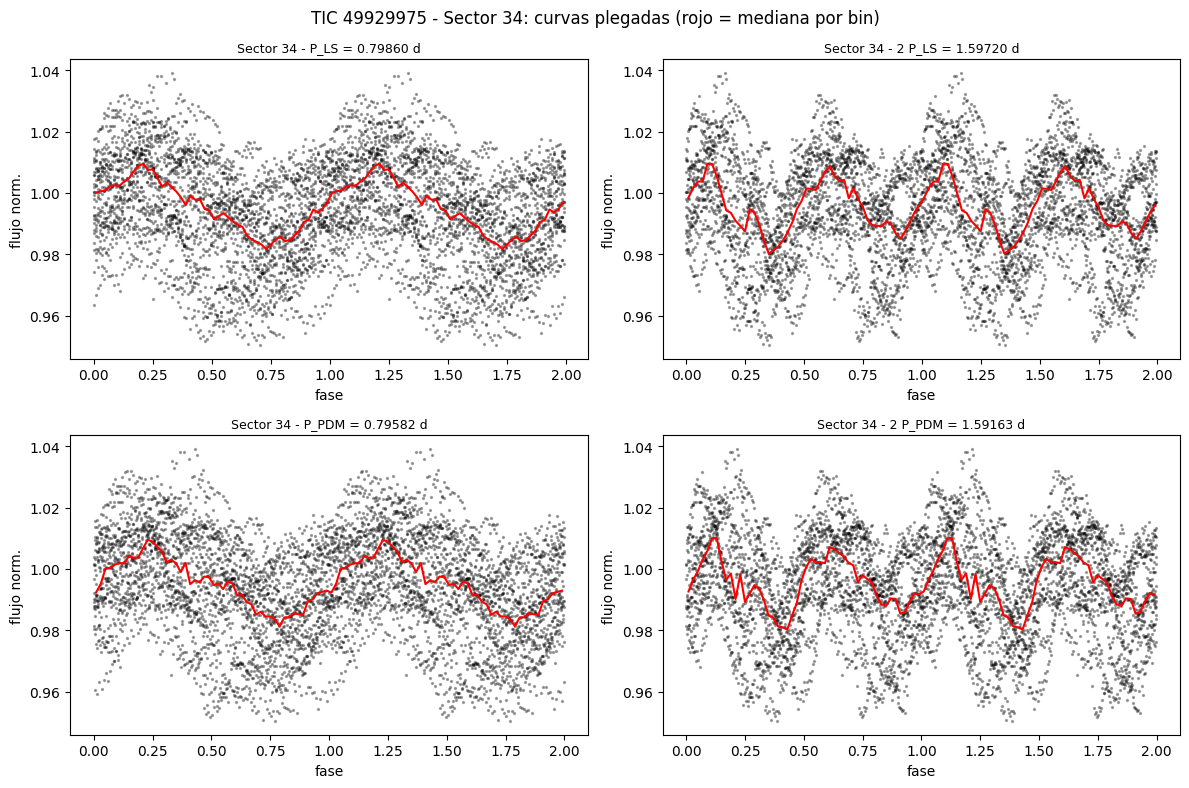


=== Sector 88 | N=11215 | baseline=27.65 d ===
LS : P=0.311076 d  power=0.1023  FAP(baluev)=2.033e-259  FAP(bootstrap)=0.000e+00
PDM: P=0.621452 d  theta_min=0.8921  FAP(perm)=9.901e-03


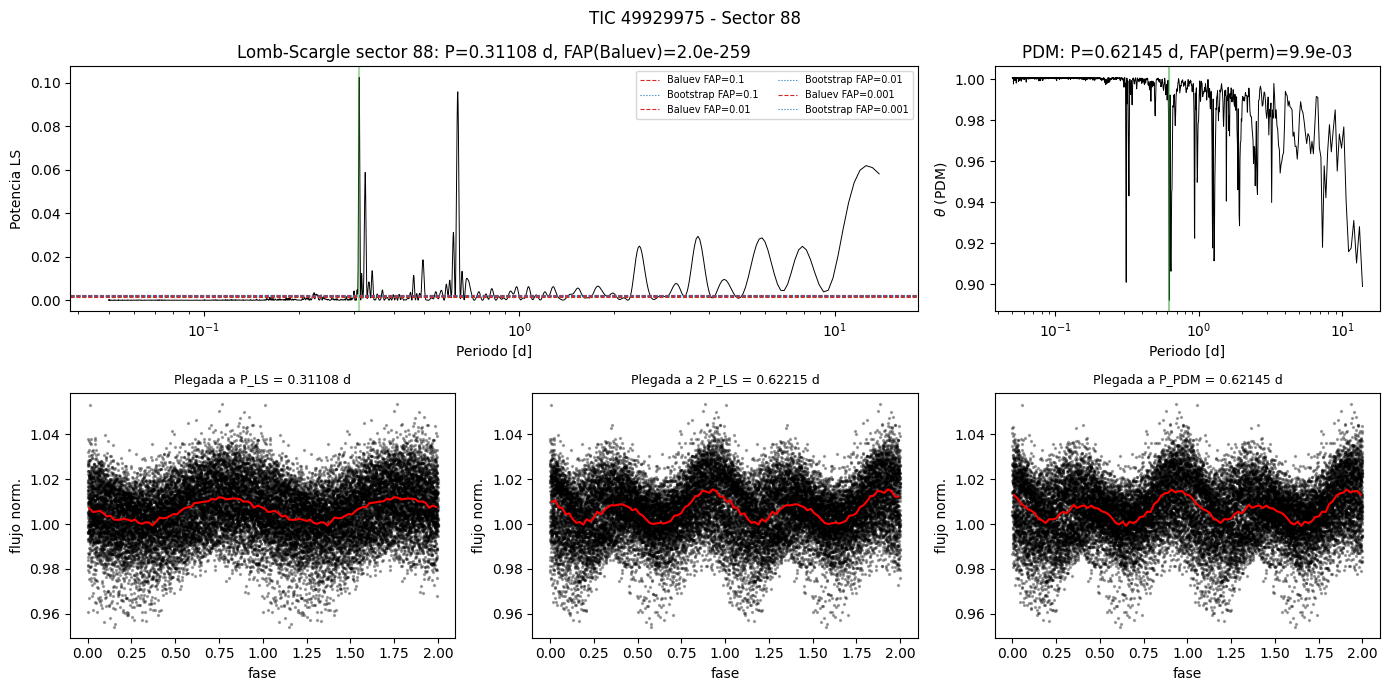

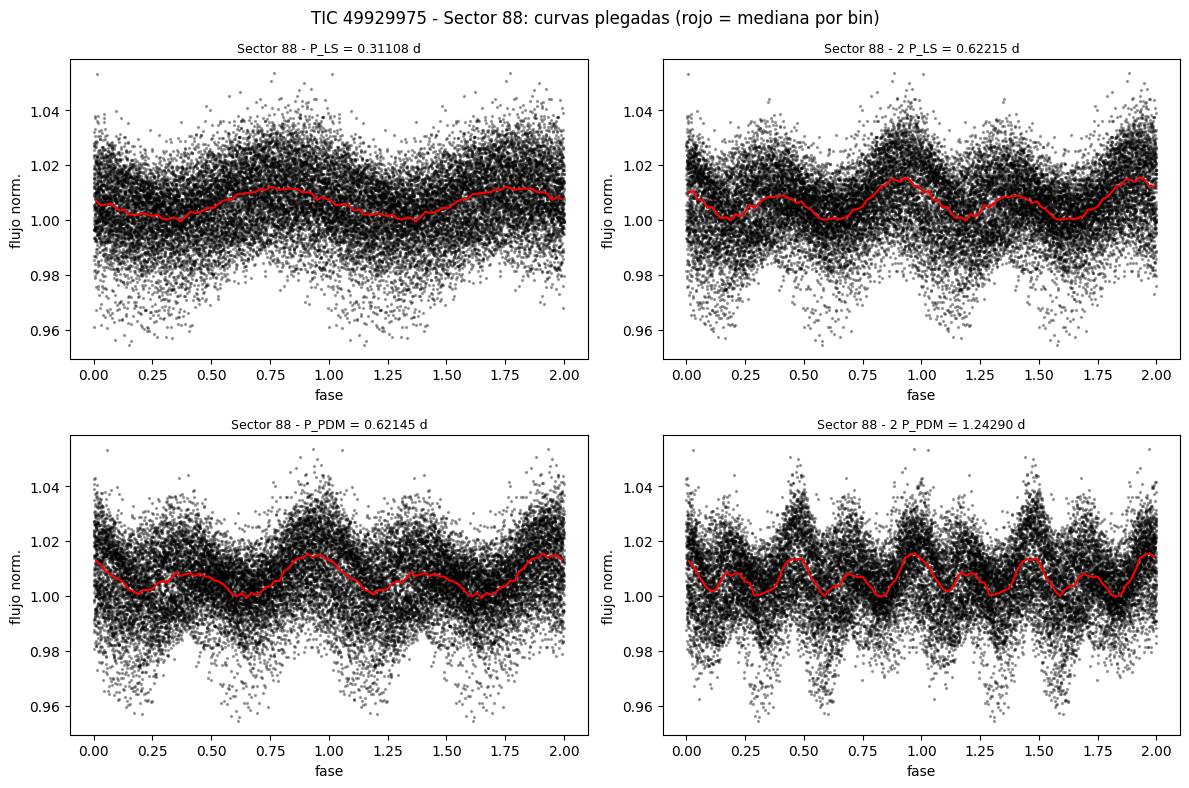

sector   N         P_LS_d             LS_power           FAP_LS_baluev      FAP_LS_bootstrap       P_PDM_d         PDM_theta_min        FAP_PDM_perm    
------ ----- ------------------ ------------------- ----------------------- ---------------- ------------------- ------------------ --------------------
     7  1064  8.118016593189774 0.19387027673407398  1.3055886924099185e-46              0.0 0.10403267740097959 0.7090317416833561 0.009900990099009901
    34  2804  0.798599892601818 0.20148397406292087 1.2867481014810083e-133              0.0  0.7958173145788152  0.805905971680213 0.009900990099009901
    88 11215 0.3110755775213628 0.10233434791257222 2.0333714159938855e-259              0.0  0.6214521088011046 0.8920946328745578 0.009900990099009901


In [10]:
"""
Periodogramas Lomb-Scargle (con FAP) y PDM para tabla_7, tabla_34 y tabla_88
Lee los ECSV generados por qlp_cbv_correction.py.
NOTA: script sin ejecutar; revisar tiempos de cómputo (bootstrap y permutaciones).
"""
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.timeseries import LombScargle

TIC = "TIC 49929975"
SECTORES = [7, 34, 88]

# --- Parámetros de búsqueda ---------------------------------------------
PMIN_D = 0.05            # periodo mínimo [d] (frecuencia máxima = 1/PMIN)
SAMPLES_PER_PEAK = 10    # sobremuestreo de la grilla de frecuencias
FAP_LEVELS = [0.1, 0.01, 0.001]
N_BOOT = 200             # remuestreos bootstrap para la FAP de LS
PDM_NBINS = 10           # bins de fase para PDM
N_PERM = 100             # permutaciones para la FAP de PDM
PERM_STEP = 5            # usar 1 de cada N periodos en las permutaciones
SEED = 42
SHOW = True              # mostrar las figuras en pantalla (notebook) además de guardarlas
rng = np.random.default_rng(SEED)


def cargar(sec):
    tab = Table.read(f"tic49929975_s{sec:02d}_qlp_corrected.ecsv")
    q = np.asarray(tab["quality"])
    t = np.asarray(tab["time_btjd"], dtype=float)
    y = np.asarray(tab["flux_corr"], dtype=float)
    dy = np.asarray(tab["flux_corr_err"], dtype=float)
    m = (q == 0) & np.isfinite(t) & np.isfinite(y) & np.isfinite(dy)
    return t[m], y[m], dy[m]


def pdm_theta(t, y, periodos, nbins=PDM_NBINS):
    """Estadístico theta de Stellingwerf (1978): s^2 / sigma^2 (menor = mejor)."""
    n = len(y)
    var = np.var(y, ddof=1)
    t0 = t.min()
    theta = np.empty(len(periodos))
    for i, P in enumerate(periodos):
        fase = ((t - t0) / P) % 1.0
        idx = np.minimum((fase * nbins).astype(int), nbins - 1)
        cnt = np.bincount(idx, minlength=nbins)
        s1 = np.bincount(idx, weights=y, minlength=nbins)
        s2 = np.bincount(idx, weights=y * y, minlength=nbins)
        ok = cnt > 1
        ss = np.sum(s2[ok] - s1[ok] ** 2 / cnt[ok])
        gl = n - ok.sum()
        theta[i] = (ss / gl) / var if gl > 0 else np.nan
    return theta


def pdm_fap(t, y, periodos, theta_obs_min):
    """FAP por permutaciones: fraccion de series barajadas con min(theta) <= observado.
    Supone ruido blanco (barajar destruye la correlacion temporal)."""
    sub = periodos[::PERM_STEP]
    minimos = np.empty(N_PERM)
    for k in range(N_PERM):
        minimos[k] = np.nanmin(pdm_theta(t, rng.permutation(y), sub))
    return (np.sum(minimos <= theta_obs_min) + 1) / (N_PERM + 1)


def plegar(ax, t, y, P, titulo, nb=50):
    fase = ((t - t.min()) / P) % 1.0
    ax.scatter(fase, y, s=2, c="k", alpha=0.3)
    ax.scatter(fase + 1, y, s=2, c="k", alpha=0.3)
    # mediana en bins de fase para ver la forma de la curva
    edges = np.linspace(0, 1, nb + 1)
    idx = np.clip(np.digitize(fase, edges) - 1, 0, nb - 1)
    med = np.array([np.median(y[idx == b]) if np.any(idx == b) else np.nan
                    for b in range(nb)])
    cen = 0.5 * (edges[:-1] + edges[1:])
    ax.plot(np.r_[cen, cen + 1], np.r_[med, med], "r-", lw=1.5)
    ax.set_title(titulo, fontsize=9)
    ax.set_xlabel("fase")
    ax.set_ylabel("flujo norm.")


resumen = []
for sec in SECTORES:
    try:
        t, y, dy = cargar(sec)
    except FileNotFoundError:
        print(f"Sector {sec}: no se encontró la tabla, se omite.")
        continue

    T = t.max() - t.min()
    fmin, fmax = 2.0 / T, 1.0 / PMIN_D
    print(f"\n=== Sector {sec} | N={len(t)} | baseline={T:.2f} d ===")

    # ---------------- Lomb-Scargle + FAP ----------------
    ls = LombScargle(t, y, dy)
    freq, power = ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax,
                               samples_per_peak=SAMPLES_PER_PEAK)
    kw = dict(minimum_frequency=fmin, maximum_frequency=fmax)
    i_ls = np.argmax(power)
    f_ls, p_ls = freq[i_ls], power[i_ls]
    P_ls = 1.0 / f_ls

    fap_baluev = ls.false_alarm_probability(p_ls, method="baluev", **kw)
    niveles_baluev = ls.false_alarm_level(FAP_LEVELS, method="baluev", **kw)
    fap_boot = ls.false_alarm_probability(
        p_ls, method="bootstrap",
        method_kwds=dict(n_bootstraps=N_BOOT, random_seed=SEED), **kw)
    niveles_boot = ls.false_alarm_level(
        FAP_LEVELS, method="bootstrap",
        method_kwds=dict(n_bootstraps=N_BOOT, random_seed=SEED), **kw)
    print(f"LS : P={P_ls:.6f} d  power={p_ls:.4f}  "
          f"FAP(baluev)={fap_baluev:.3e}  FAP(bootstrap)={fap_boot:.3e}")

    # ---------------- PDM ----------------
    periodos = 1.0 / freq
    theta = pdm_theta(t, y, periodos)
    i_pdm = np.nanargmin(theta)
    P_pdm, th_min = periodos[i_pdm], theta[i_pdm]
    fap_pdm = pdm_fap(t, y, periodos, th_min)
    print(f"PDM: P={P_pdm:.6f} d  theta_min={th_min:.4f}  FAP(perm)={fap_pdm:.3e}")

    # ---------------- Guardar periodogramas ----------------
    tabper = Table({"freq_cpd": freq, "period_d": periodos,
                    "ls_power": power, "pdm_theta": theta})
    tabper.meta.update(TARGET=TIC, SECTOR=sec)
    tabper.write(f"periodogramas_s{sec:02d}.ecsv", format="ascii.ecsv", overwrite=True)

    # ---------------- Figura ----------------
    fig = plt.figure(figsize=(14, 7))
    gs = fig.add_gridspec(2, 3)
    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(periodos, power, "k", lw=0.7)
    for lev, nb, nbo in zip(FAP_LEVELS, niveles_baluev, niveles_boot):
        ax1.axhline(nb, ls="--", lw=0.8, c="tab:red", label=f"Baluev FAP={lev}")
        ax1.axhline(nbo, ls=":", lw=0.8, c="tab:blue", label=f"Bootstrap FAP={lev}")
    ax1.axvline(P_ls, c="tab:green", alpha=0.4)
    ax1.set_xscale("log"); ax1.set_xlabel("Periodo [d]"); ax1.set_ylabel("Potencia LS")
    ax1.set_title(f"Lomb-Scargle sector {sec}: P={P_ls:.5f} d, FAP(Baluev)={fap_baluev:.1e}")
    ax1.legend(fontsize=7, ncol=2)

    ax2 = fig.add_subplot(gs[0, 2])
    ax2.plot(periodos, theta, "k", lw=0.7)
    ax2.axvline(P_pdm, c="tab:green", alpha=0.5)
    ax2.set_xscale("log"); ax2.set_xlabel("Periodo [d]"); ax2.set_ylabel(r"$\theta$ (PDM)")
    ax2.set_title(f"PDM: P={P_pdm:.5f} d, FAP(perm)={fap_pdm:.1e}")

    plegar(fig.add_subplot(gs[1, 0]), t, y, P_ls, f"Plegada a P_LS = {P_ls:.5f} d")
    plegar(fig.add_subplot(gs[1, 1]), t, y, 2 * P_ls, f"Plegada a 2 P_LS = {2*P_ls:.5f} d")
    plegar(fig.add_subplot(gs[1, 2]), t, y, P_pdm, f"Plegada a P_PDM = {P_pdm:.5f} d")
    fig.suptitle(f"{TIC} - Sector {sec}")
    fig.tight_layout()
    fig.savefig(f"periodogramas_s{sec:02d}.png", dpi=150)
    if SHOW:
        plt.show()
    plt.close(fig)

    # ---------------- Figura de plegadas (más grande) ----------------
    cands = [(P_ls, "P_LS"), (2 * P_ls, "2 P_LS"), (P_pdm, "P_PDM"), (2 * P_pdm, "2 P_PDM")]
    figf, axf = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (P, nom) in zip(axf.ravel(), cands):
        plegar(ax, t, y, P, f"Sector {sec} - {nom} = {P:.5f} d")
    figf.suptitle(f"{TIC} - Sector {sec}: curvas plegadas (rojo = mediana por bin)")
    figf.tight_layout()
    figf.savefig(f"folds_s{sec:02d}.png", dpi=150)
    if SHOW:
        plt.show()
    plt.close(figf)

    resumen.append((sec, len(t), P_ls, p_ls, fap_baluev, fap_boot, P_pdm, th_min, fap_pdm))

# ---------------- Tabla resumen ----------------
if resumen:
    cols = list(zip(*resumen))
    res = Table(cols, names=("sector", "N", "P_LS_d", "LS_power", "FAP_LS_baluev",
                             "FAP_LS_bootstrap", "P_PDM_d", "PDM_theta_min", "FAP_PDM_perm"))
    res.write("resultados_periodogramas.ecsv", format="ascii.ecsv", overwrite=True)
    res.pprint_all()